<!-- 2026-11-06 09:12 KST -->
# 원터치 클리너 앱 로고 만들기 (틸론 주피터)

- 틸론(교내 GPU 서버)의 주피터 노트북에서 Python **matplotlib**으로 앱 로고(초록 방패와 체크 표시)를 직접 그렸다.
- 이 파일은 틸론 노트북의 코드를 옮겨 저장소에 보관한 것이다. 같은 코드를 다시 실행해 같은 그림이 나오는 것을 확인했다(2026-11-06).
- 결과 이미지 `cleaner_app_logo.png`(300dpi)를 앱에 반영했다.
  - 앱 상단 로고: `public/logo.png`
  - 브라우저 탭과 홈 화면 추가용 아이콘: `public/icon-180.png`, `icon-192.png`, `icon-512.png`, `icon-maskable-512.png`

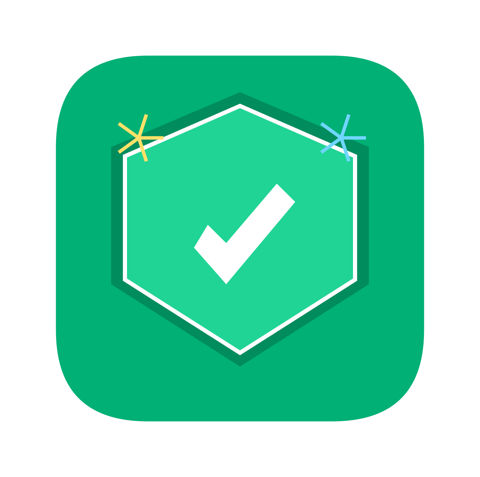

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 1. 도화지(캔버스) 설정
fig, ax = plt.subplots(figsize=(6, 6), facecolor='white')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

# 2. 앱 아이콘 배경 (둥근 사각형)
app_bg = patches.FancyBboxPatch((10, 10), 80, 80, boxstyle="round,pad=0,rounding_size=20",
                                facecolor='#00b074', edgecolor='none')
ax.add_patch(app_bg)

# 3. 방패 그림자 효과
shield_shadow = patches.Polygon([[50, 82], [78, 70], [78, 40], [50, 22], [22, 40], [22, 70]],
                                closed=True, facecolor='#008c5c', edgecolor='none')
ax.add_patch(shield_shadow)

# 4. 메인 방패 심볼
shield = patches.Polygon([[50, 79], [75, 68], [75, 41], [50, 25], [25, 41], [25, 68]],
                         closed=True, facecolor='#20d495', edgecolor='white', linewidth=3)
ax.add_patch(shield)

# 5. 방패 내부 체크 마크
check = patches.Polygon([[40, 48], [47, 40], [62, 58], [58, 62], [47, 49], [43, 53]],
                        closed=True, facecolor='white', edgecolor='none')
ax.add_patch(check)

# 6. 상단 반짝이(스파크) 장식 함수
def draw_star(x, y, size, color):
    angles = np.linspace(0, 2*np.pi, 5, endpoint=False)
    for a in angles:
        ax.plot([x, x + size*np.cos(a)], [y, y + size*np.sin(a)], color=color, lw=2.5)

draw_star(28, 72, 5, '#ffe169')
draw_star(72, 72, 5, '#70d6ff')

# 7. 이미지 출력 및 파일 저장
plt.savefig('cleaner_app_logo.png', bbox_inches='tight', dpi=300)
plt.show()